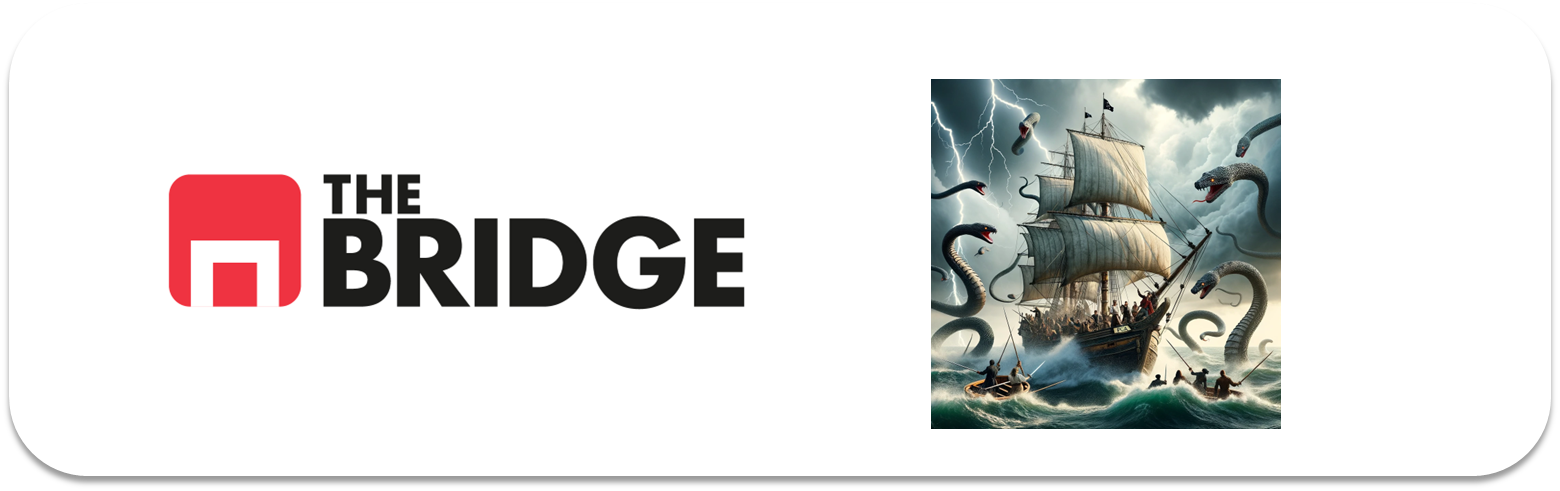

## PRÁCTICA: **Selección de Features**

* La práctica de esta unidad consiste en hacer una comparativa de diferentes técnicas de selección de features sobre un dataset ya conocido.

### Descripción General y Objetivo

El objetivo de la práctica es que juegues con las diferentes técnicas de selección de features sobre un problema de clasificación. Para ello, tendrás que cargar el dataset de credit scoring que tienes en la carpeta `data` de la unidad (`../data`) y que ya hemos trabajado anteriormente. A partir de ahí tendrás que probar diferentes técnicas de selección de features y compararlas entre sí para escoger, finalmente, el conjunto más sencillo con más potencia. 

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook.

In [1]:
import bootcampviztools as bt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from collections import Counter
from lightgbm import LGBMClassifier
from scipy.stats import mannwhitneyu
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, SelectFromModel, RFE, SequentialFeatureSelector
from sklearn.metrics import mutual_info_score, classification_report
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from xgboost import XGBClassifier


### Detalles e Instrucciones

El objetivo es que construyas un modelo final de clasificación sobre la variable "SeriousDlqin2yrs" del dataset que encontrarás en `data`.  

Sigue los pasos del proceso de ML que hemos aprendido para problemas supervisados con el dataset que encontrarás en `data`, pero con las siguientes salvedades:

1. Deshazte de las filas con nulos: para este ejercicio no nos importan. Convierte las features NumberOf... que creas conveniente a categóricas con 2 o 3 niveles a lo sumo.

2. A la hora de hacer el miniEDA aplica los siguientes análisis y selección de features: 
    1. Análisis visual combinado con filtrado por valores de correlación y umbral de varianza.
    2. Selección de features numéricas mediante SelectKBest y ANOVA, y selección de features categóricas mediante Mutual Information.
    3. Selección de las mejores features a través de un modelo intermedio (usando SelectFromModel)
    4. Selección de las mejores features empleando RFE.
    5. Selección de las mejores features empleando SFS.
    6. Selección de las mejores features mediante un sistema de hard-voting aplicado a lo obtenido en los pasos 1 a 5 anteriores.

    Para cada paso anterior (salvo el 1) se pide obtener una lista de features de "primera división" con un número de variables no superior a 6 (pueden ser menos).

3. Escoge tres modelos y, a la hora de compararlos para escoger el mejor, entrénalos con validación cruzada empleando las seis listas obtenidas anteriormente. Es decir, tendrás 18 (6*3) medidas (emplea la métrica que creas más conveniente y, si no se te ocurre ninguna, el recall medio). Escoge el mejor modelo y la mejor selección de features.

4. Optimiza los hiperparámetros del mejor modelo. Evalúalo contra test.


*Pasos ML:*  

*1. Entender el problema -> Tener claro lo siguiente: tipo de aprendizaje, modelos posibles, target o no, métrica o sistema de evaluación (para no supervisados esto es muy importante). EN ESTA PRÁCTICA nos quedamos con un modelo supervisado de clasificación cuyo target es el posible impago de más de 90 días en los próximos dos años, y con el recall medio como métrica (por lo desbalanceado del target, aunque todavía no lo hayamos visto :-)).*   
  
*2. Cargar datos, primer vistazo*

In [2]:
df = pd.read_csv("../data/credit_npo.csv")
df

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,0,0.081892,37,0,0.070709,5656.0,12,1,0,0,0.0
1,0,0.023413,74,0,0.209197,4870.0,9,0,1,0,0.0
2,0,0.000000,43,0,0.080784,5000.0,2,0,0,0,2.0
3,0,0.492754,44,0,0.412735,7333.0,4,0,2,0,3.0
4,0,1.000000,63,0,0.000000,8333.0,3,0,0,0,1.0
...,...,...,...,...,...,...,...,...,...,...,...
12532,0,0.197116,59,0,0.290216,5140.0,6,0,1,0,0.0
12533,0,0.036726,62,0,0.884985,5833.0,12,0,1,0,0.0
12534,0,0.120313,49,0,0.577676,6333.0,7,0,2,0,2.0
12535,0,0.252566,63,0,0.037640,14000.0,9,0,0,0,1.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12537 entries, 0 to 12536
Data columns (total 11 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   SeriousDlqin2yrs                      12537 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  12537 non-null  float64
 2   age                                   12537 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  12537 non-null  int64  
 4   DebtRatio                             12537 non-null  float64
 5   MonthlyIncome                         11816 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       12537 non-null  int64  
 7   NumberOfTimes90DaysLate               12537 non-null  int64  
 8   NumberRealEstateLoansOrLines          12537 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  12537 non-null  int64  
 10  NumberOfDependents                    12360 non-null  float64
dtypes: float64(4), 

*Tal y como nos indican en el enunciado nos deshacemos de las filas con nulos. Esto es porque es un ejercicio académico, pero en la vida real ¿qué implicación tiene deshacerse de filas con nulos? Que en los datos futuros para predecir tendremos que tener todas las columnas informadas o reconstruirlas de alguna forma.* 

In [4]:
df.dropna(inplace = True) # df = df.dropna()
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11816 entries, 0 to 12536
Data columns (total 11 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   SeriousDlqin2yrs                      11816 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  11816 non-null  float64
 2   age                                   11816 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  11816 non-null  int64  
 4   DebtRatio                             11816 non-null  float64
 5   MonthlyIncome                         11816 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       11816 non-null  int64  
 7   NumberOfTimes90DaysLate               11816 non-null  int64  
 8   NumberRealEstateLoansOrLines          11816 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  11816 non-null  int64  
 10  NumberOfDependents                    11816 non-null  float64
dtypes: float64(4), int64

In [5]:
target = "SeriousDlqin2yrs"

3. Train y Test


In [6]:
train_set, test_set = train_test_split(df, test_size = 0.2, random_state= 42)

4. MiniEDA

*4.1 Análisis del target*

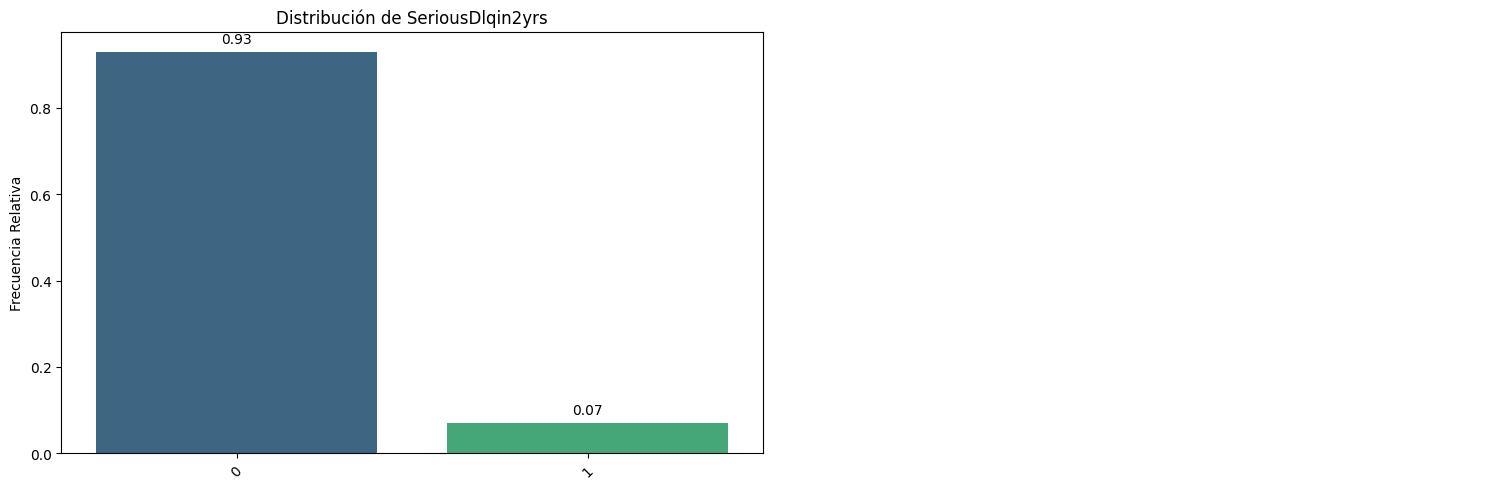

In [7]:
bt.pinta_distribucion_categoricas(train_set, [target], True, True)

*Ya conocíamos este dataset, en el que hay un desequilibrio importante. Aunque vamos a emplear el recall medio ("balanced_accuracy"), este tipo de desequilibrios suele pedir métricas por clase, es decir, la precisión de la clase mayoritaria o el recall de la minoritaria, o viceversa.*

*4.2 Clasificación y transformación de las variables: Vamos a ver cuáles son numéricas y cuáles categóricas y, además, como nos piden que transformemos las variables "NumberOf" en categóricas lo haremos también. Recuerda que si las clasificamos así es porque el tratamiento y análisis es diferente según sean de un tipo u otro.*

*Para ver si son categóricas o numéricas podemos utilizar nuestras funciones del toolbox o usar un describe y un hist:*

In [8]:
train_set.describe().T

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,9452.0,0.070144,0.255403,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,9452.0,0.335207,0.362233,0.0,0.034869,0.179211,0.587533,6.0
age,9452.0,51.491536,14.499298,21.0,41.000000,51.000000,62.000000,101.0
NumberOfTime30-59DaysPastDueNotWorse,9452.0,0.343314,2.930489,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,9452.0,0.486047,2.505031,0.0,0.146204,0.297564,0.477876,96.0
MonthlyIncome,9452.0,6868.428058,12580.543336,0.0,3466.000000,5441.000000,8300.000000,702500.0
NumberOfOpenCreditLinesAndLoans,9452.0,8.794647,5.139555,0.0,5.000000,8.000000,11.000000,49.0
NumberOfTimes90DaysLate,9452.0,0.180279,2.889984,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,9452.0,1.064325,1.148156,0.0,0.000000,1.000000,2.000000,19.0
NumberOfTime60-89DaysPastDueNotWorse,9452.0,0.152772,2.870119,0.0,0.000000,0.000000,0.000000,98.0


(10, 2)


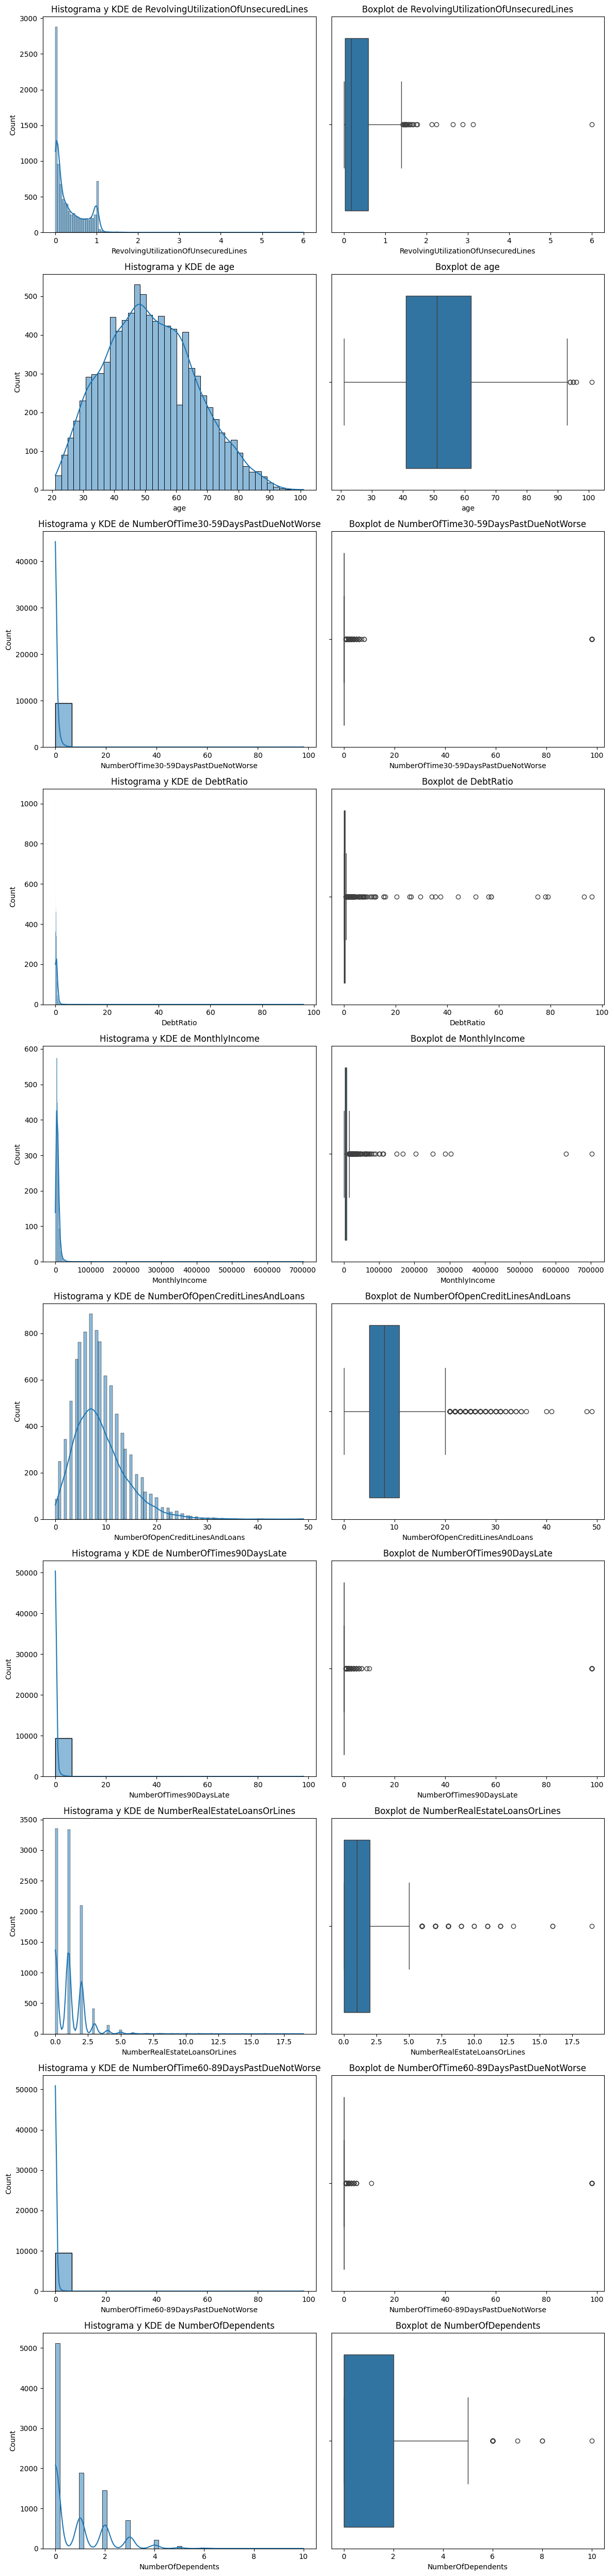

In [9]:
bt.plot_combined_graphs(train_set, [col for col in train_set.columns if col != target])

* *RevolvingUtilizationOfUnsecuredLines*: Numérica continua
* *age*: Numérica discreta
* *NumberOfTime30-59DaysPastDueNotWorse*: El valor 98 lo distorsiona, si nos fijamos en sus cuantiles (0) y en el combinado de histograma y caja, es claramente categorizable. Haremos un value_counts para decidir esa categorización.
* *DebtRatio*: La consideramos numérica continua, por rango y valores.
* *MonthlyIncome*: Numérica continua
* *NumberOfOpenCreditLinesAndLoans*: Numérica discreta pero por cantidad de valores la consideramos numérica continua.
* *NumberOfTimes90DaysLate*: Le ocurre lo mismo que a NumberOfTime30-59DaysPastDueNotWorse. Nos fijaremos en el value_counts para ver su categorización.
* *NumberRealEstateLoansOrLines*: Esta es una feature con outliers dispersos pero que parece concentrada en 5 valores, miraremos su value_counts y su bivariante con el target para tomar una decisión que probablemente será categorizarla. 
* *NumberOfTime60-89DaysPastDueNotWorse*: Como las otras dos variables del estilo (NumberOfTime30-59DaysPastDueNotWorse, NumberOfTimes90DaysLate), se concentra en 0 y tiene varios outliers y está sesgada por el valor 98. La categorizaremos después de ver su value_counts.
* *NumberOfDependents*: Numérica discreta que no tocaremos.

*Ya podemos crear la lista de numéricas (continuas y discretas) que vamos a tratar:*

In [10]:
features_num = ["RevolvingUtilizationOfUnsecuredLines",
                "age",
                "DebtRatio",
                "MonthlyIncome",
                "NumberOfOpenCreditLinesAndLoans",
                "NumberOfDependents"]

In [11]:
train_set["NumberOfDependents"].value_counts(True) * 100

NumberOfDependents
0.0     54.221329
1.0     19.942869
2.0     15.308929
3.0      7.490478
4.0      2.211172
5.0      0.581887
6.0      0.201016
8.0      0.021160
7.0      0.010580
10.0     0.010580
Name: proportion, dtype: float64

In [12]:
columnas_numberof = [col for col in df.columns if col.startswith("NumberOf")]
for col in columnas_numberof:
    distribucion_porcentaje = (df[col].value_counts(normalize= True, dropna= False).sort_index())
    
    porcentaje_ceros = distribucion_porcentaje.get(0, 0)
    print(f"\n{col} | valores_unicos =  {df[col].nunique()} | porcentaje_0 = {porcentaje_ceros:.2%}")
    print((distribucion_porcentaje.head(10) * 100).round(2))


NumberOfTime30-59DaysPastDueNotWorse | valores_unicos =  10 | porcentaje_0 = 83.09%
NumberOfTime30-59DaysPastDueNotWorse
0     83.09
1     11.46
2      3.36
3      1.07
4      0.54
5      0.19
6      0.17
7      0.01
8      0.02
98     0.08
Name: proportion, dtype: float64

NumberOfOpenCreditLinesAndLoans | valores_unicos =  43 | porcentaje_0 = 0.95%
NumberOfOpenCreditLinesAndLoans
0    0.95
1    2.60
2    3.77
3    5.40
4    7.18
5    8.15
6    8.73
7    9.39
8    8.54
9    8.17
Name: proportion, dtype: float64

NumberOfTimes90DaysLate | valores_unicos =  13 | porcentaje_0 = 94.41%
NumberOfTimes90DaysLate
0    94.41
1     3.33
2     1.20
3     0.46
4     0.26
5     0.12
6     0.05
7     0.03
8     0.03
9     0.01
Name: proportion, dtype: float64

NumberOfTime60-89DaysPastDueNotWorse | valores_unicos =  8 | porcentaje_0 = 94.84%
NumberOfTime60-89DaysPastDueNotWorse
0     94.84
1      4.05
2      0.72
3      0.15
4      0.12
5      0.03
11     0.01
98     0.08
Name: proportion, dtype: 

*Analizamos con un poco más de detalle "NumberRealEstateLoansOrLines" para decidir si categórica o numérica:*

In [13]:
train_set["NumberRealEstateLoansOrLines"].value_counts(True) * 100

NumberRealEstateLoansOrLines
0     35.505713
1     35.272958
2     22.164621
3      4.369446
4      1.449429
5      0.708845
6      0.201016
8      0.084638
7      0.084638
11     0.031739
9      0.031739
12     0.031739
16     0.021160
10     0.021160
13     0.010580
19     0.010580
Name: proportion, dtype: float64

*Existen bastantes valores entre 0 y 4 y ya menos en 5, y a partir de ahí casi no hay instancias (filas del dataframe) con 6 o más. Podríamos crear una categoría "más de 6" o 7 que incluya todos los valores iguales o por encima de 6; por simplicidad, la dejamos tal cual y la consideramos numérica discreta.*  

*¿Pero entonces cuándo te quedas con una numérica discreta y cuándo la consideras categórica? Si tengo tiempo haría las dos consideraciones. ¿La diferencia? El hecho de que los valores 6 a 19 los convertiría en un único valor "7" y luego trataría ambas como ordinales (no haría otra codificación). Probaría las "dos" features para ver cuál aporta más. Como no tenemos más tiempo, lo dejo en numérica discreta, en definitiva, no la toco*

In [14]:
features_num.append("NumberRealEstateLoansOrLines")

In [15]:
features_num

['RevolvingUtilizationOfUnsecuredLines',
 'age',
 'DebtRatio',
 'MonthlyIncome',
 'NumberOfOpenCreditLinesAndLoans',
 'NumberOfDependents',
 'NumberRealEstateLoansOrLines']

*Categoricemos NumberOfTime30-59DaysPastDueNotWorse, NumberOfTime60-89DaysPastDueNotWorse, NumberOfTimes90DaysLate:*

In [16]:
train_set["NumberOfTime30-59DaysPastDueNotWorse"].value_counts(True)

NumberOfTime30-59DaysPastDueNotWorse
0     0.831147
1     0.113521
2     0.033644
3     0.010897
4     0.005607
5     0.002116
6     0.001904
98    0.000846
8     0.000212
7     0.000106
Name: proportion, dtype: float64

*Una regla del dedo gordo: hacer "categorías" de cualquier valor discreto con 10% o más de instancias. En este caso, aplicando esa regla, tendríamos 0, 1 y más de 1. Voy a hacer 3 y las voy a "codificar" ya como 0, 1 y 2.*

In [17]:
n_corto = "NumberOfTime30-59DaysPastDueNotWorse"
train_set[train_set[target] == 0][n_corto].value_counts(True)

NumberOfTime30-59DaysPastDueNotWorse
0     0.855956
1     0.103083
2     0.026852
3     0.007851
4     0.003413
5     0.001138
6     0.001024
98    0.000341
8     0.000228
7     0.000114
Name: proportion, dtype: float64

In [18]:
n_corto = "NumberOfTime30-59DaysPastDueNotWorse"
train_set[train_set[target] == 1][n_corto].value_counts(True)

NumberOfTime30-59DaysPastDueNotWorse
0     0.502262
1     0.251885
2     0.123680
3     0.051282
4     0.034691
5     0.015083
6     0.013575
98    0.007541
Name: proportion, dtype: float64

In [19]:
# Me simplifico la vida con el nombre
n_corto = "NumberOfTime30-59DaysPastDueNotWorse"

# Método 1, con pd.cut
labels = [0,1,2] # Cambio 

train_set["N30-59"] = pd.cut(train_set[n_corto], bins = [-1,0,1,np.inf], labels = labels, right= True).astype(int) # right a True para incluir los valores "a la derecha" en el bin (es decir -1,0 incluye a todos los valores >-1 y <= 0)
test_set["N30-59"] = pd.cut(test_set[n_corto], bins = [-1,0,1,np.inf], labels = labels, right= True).astype(int) 
train_set["N30-59"].value_counts(True)


N30-59
0    0.831147
1    0.113521
2    0.055332
Name: proportion, dtype: float64

*Además podemos comprobar si esa codificación "refleja" la tendencia a "tener deuda":*

In [20]:
train_set[train_set[target] == 1]["N30-59"].value_counts(True)

N30-59
0    0.502262
1    0.251885
2    0.245852
Name: proportion, dtype: float64

*Viendo esto podríamos incluso haber dejado solo dos categorías (fíjate en que las frecuencias de "impagadores" son similares para 1 y para 2), pero nos vamos a quedar con las tres por no complicar más el notebook (sí, si tuviéramos más tiempo y espacio lo haríamos con dos categorizaciones también :-). Siguiente*

In [21]:
train_set["NumberOfTime60-89DaysPastDueNotWorse"].value_counts(True)

NumberOfTime60-89DaysPastDueNotWorse
0     0.947207
1     0.040521
2     0.008041
3     0.001481
4     0.001375
98    0.000846
5     0.000423
11    0.000106
Name: proportion, dtype: float64

*Aquí escogemos dos categorías: 0, y 1 o más:*

In [22]:
train_set["NumberOfTime60-89DaysPastDueNotWorse"] != 0

11145    False
2012     False
5428     False
12130    False
36       False
         ...  
11966    False
5512     False
5719     False
922      False
7727     False
Name: NumberOfTime60-89DaysPastDueNotWorse, Length: 9452, dtype: bool

In [23]:
(train_set["NumberOfTime60-89DaysPastDueNotWorse"] != 0).astype(int)

11145    0
2012     0
5428     0
12130    0
36       0
        ..
11966    0
5512     0
5719     0
922      0
7727     0
Name: NumberOfTime60-89DaysPastDueNotWorse, Length: 9452, dtype: int32

In [24]:
train_set["N60-89"] = (train_set["NumberOfTime60-89DaysPastDueNotWorse"] > 0).astype(int)
test_set["N60-89"] = (test_set["NumberOfTime60-89DaysPastDueNotWorse"] > 0).astype(int)
train_set["N60-89"].value_counts(True)

N60-89
0    0.947207
1    0.052793
Name: proportion, dtype: float64

In [25]:
train_set[train_set[target] == 1]["N60-89"].value_counts(True)

N60-89
0    0.746606
1    0.253394
Name: proportion, dtype: float64

In [26]:
train_set[train_set[target] == 0]["N60-89"].value_counts(True)

N60-89
0    0.962339
1    0.037661
Name: proportion, dtype: float64

*Tiene buena pinta (luego lo analizamos con detalle)*

In [27]:
train_set["NumberOfTimes90DaysLate"].value_counts(True)

NumberOfTimes90DaysLate
0     0.943610
1     0.033115
2     0.012590
3     0.004655
4     0.002751
5     0.001481
98    0.000846
6     0.000529
7     0.000212
9     0.000106
10    0.000106
Name: proportion, dtype: float64

*Dos categorías: 0, y 1 o más:*

In [28]:
train_set["N90"] = (train_set["NumberOfTimes90DaysLate"] > 0).astype(int)
test_set["N90"] = (test_set["NumberOfTimes90DaysLate"] > 0).astype(int)
train_set["N90"].value_counts(True)

N90
0    0.94361
1    0.05639
Name: proportion, dtype: float64

In [29]:
train_set[train_set[target] == 1]["N90"].value_counts(True)

N90
0    0.642534
1    0.357466
Name: proportion, dtype: float64

In [30]:
train_set[train_set[target] == 0]["N90"].value_counts(True)

N90
0    0.966322
1    0.033678
Name: proportion, dtype: float64

*Igual que la anterior tiene buena pinta. Y ya tenemos nuestras categóricas:*

In [31]:
features_cat = ["N30-59","N60-89","N90"]
features_cat


['N30-59', 'N60-89', 'N90']

In [32]:
features_num

['RevolvingUtilizationOfUnsecuredLines',
 'age',
 'DebtRatio',
 'MonthlyIncome',
 'NumberOfOpenCreditLinesAndLoans',
 'NumberOfDependents',
 'NumberRealEstateLoansOrLines']

In [33]:
target

'SeriousDlqin2yrs'

4.3 **Análisis visual con estadísticos matemáticos**

*Hagamos nuestros análisis bivariantes para hacer la selección de las variables "visualmente", como hemos venido haciendo hasta ahora. Empezamos con las categóricas*

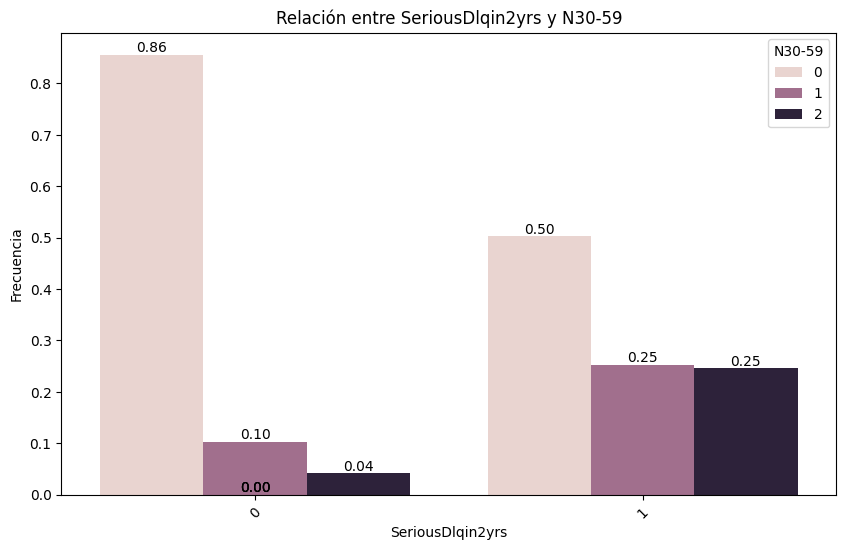

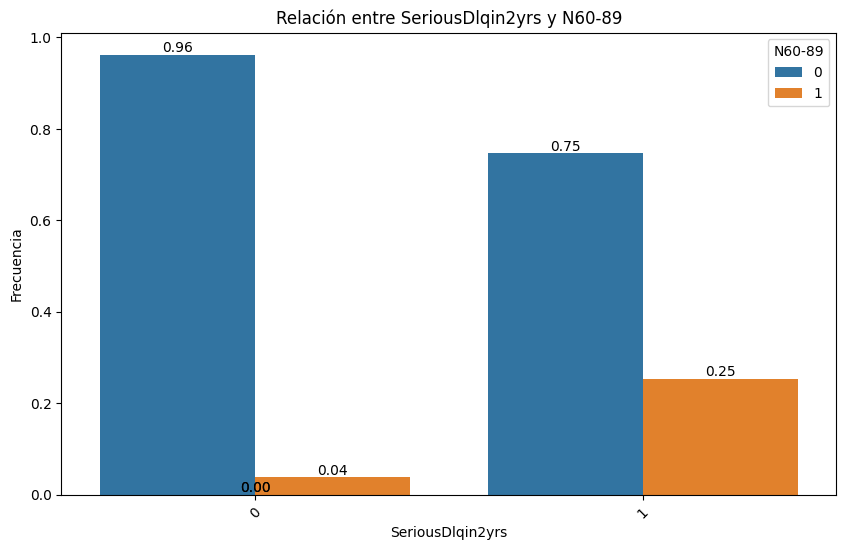

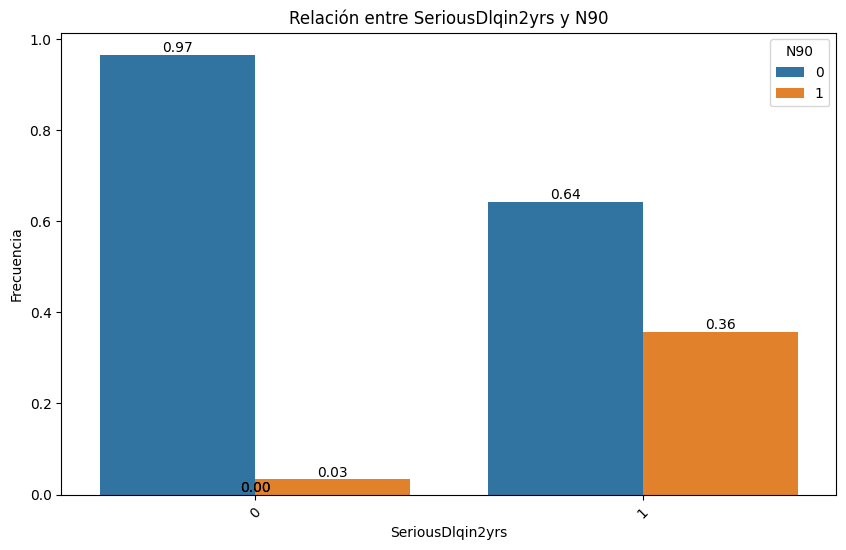

In [34]:
for col in features_cat:
    bt.plot_categorical_relationship_fin(train_set, target, col, True, True)

*Las tres tienen diferencias destacadas según el valor del target, son de "primera división"*

In [35]:
features_visual = features_cat.copy()

*Vamos con las numéricas*

In [36]:
len(features_num + [target])

8

In [37]:
# sns.pairplot(train_set[features_num + [target]], hue = target)

*Gráficas demasiado pequeñas, usaremos nuestras tools*

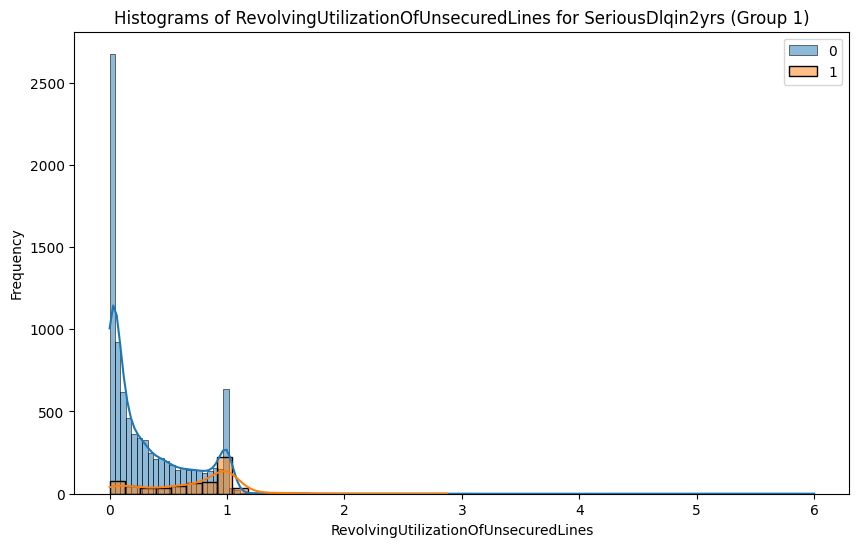

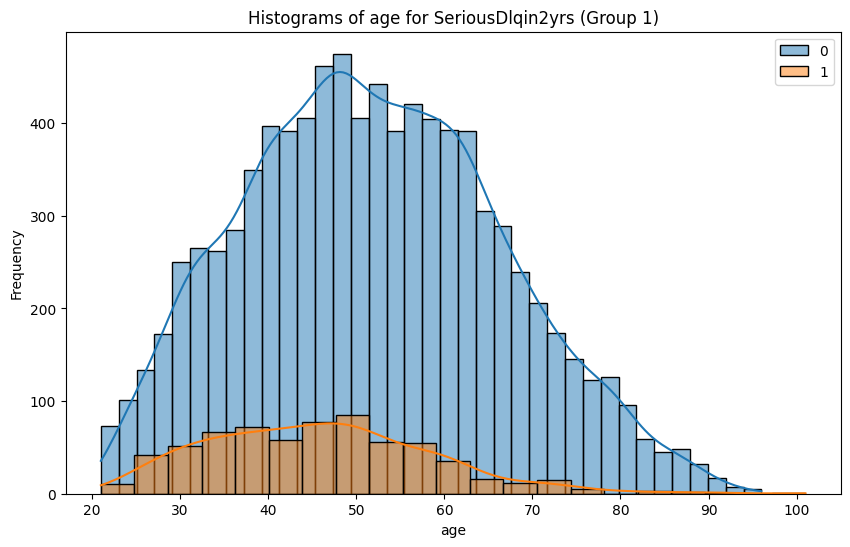

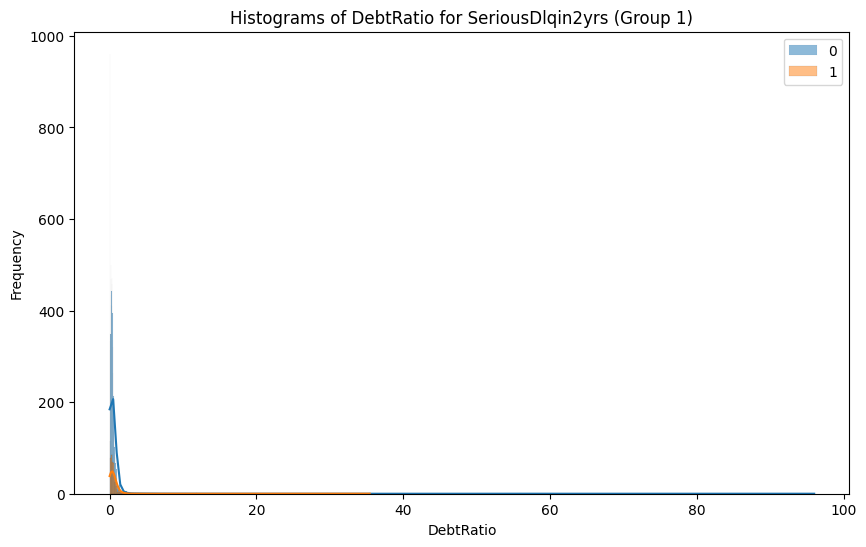

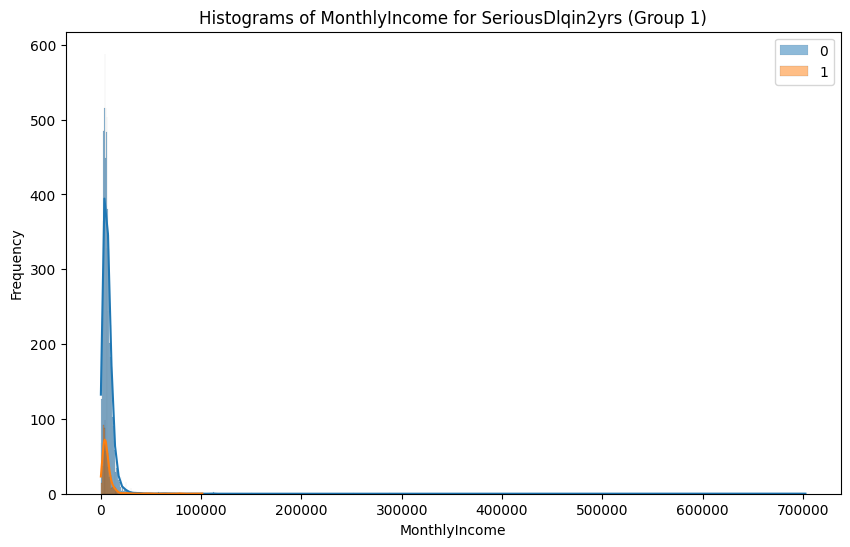

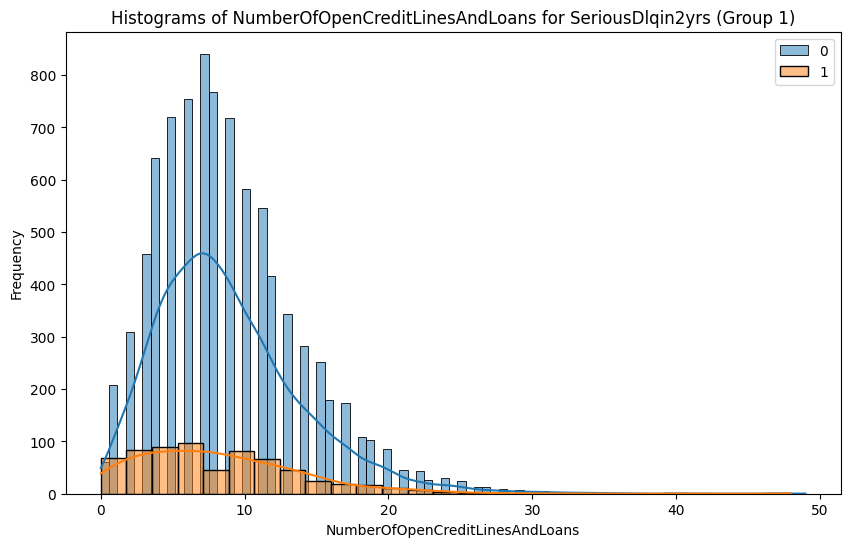

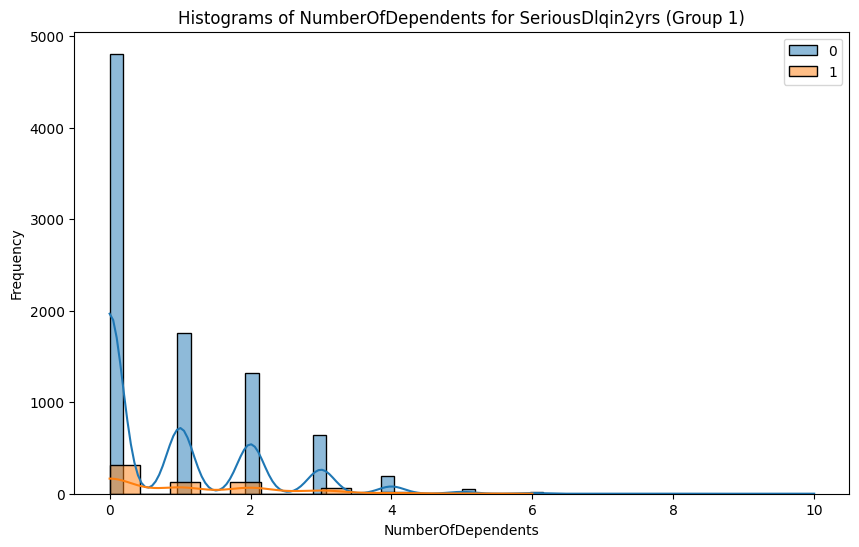

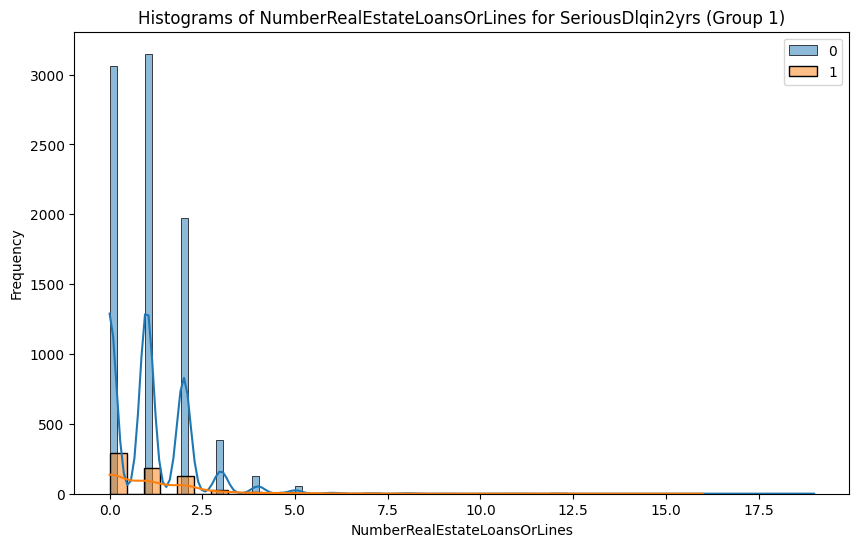

In [38]:
for col in features_num:
    bt.plot_grouped_histograms(train_set, cat_col= target, num_col= col, group_size= 2)

*Podemos hacer unas pequeñas modificaciones al histplot de Seaborn para que el desbalanceo del target no nos impida ver nada:*

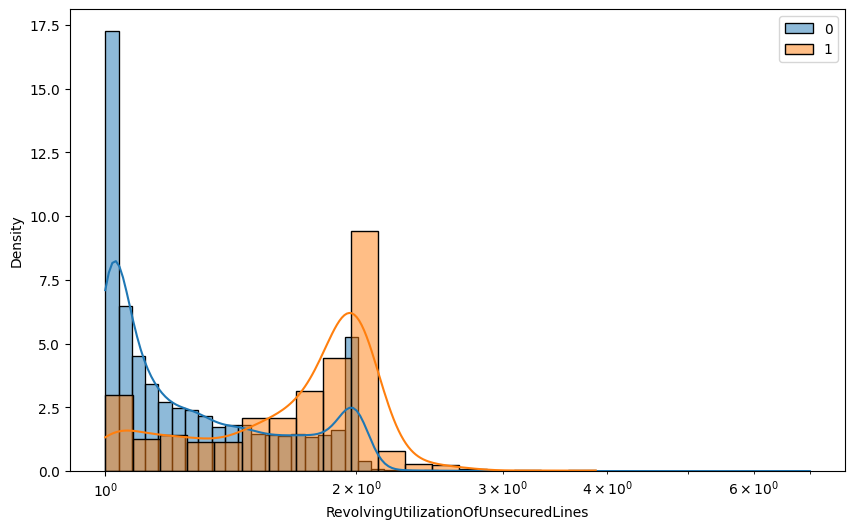

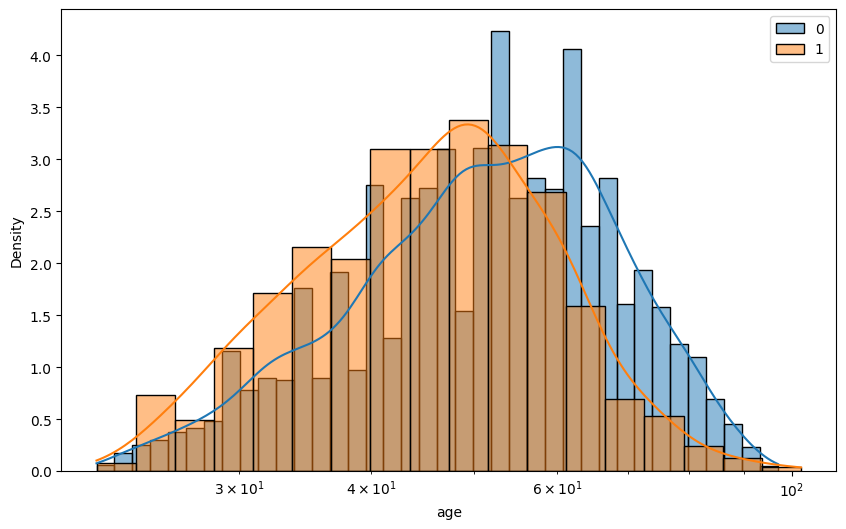

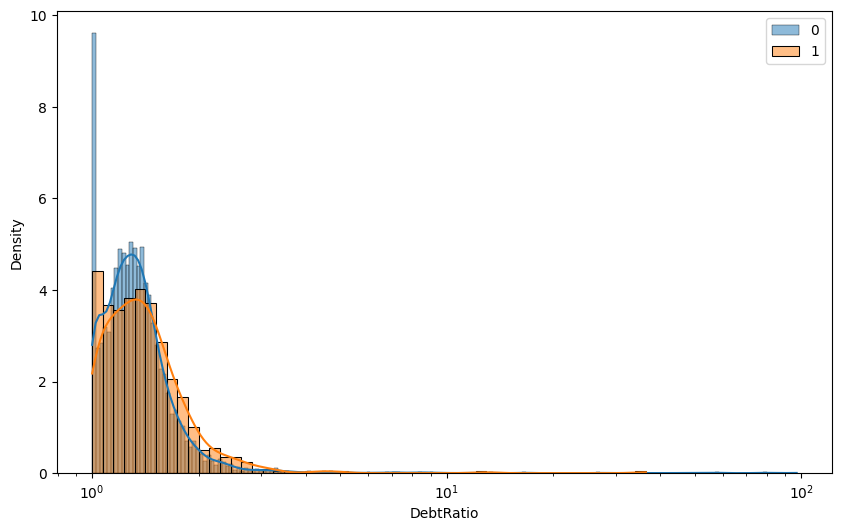

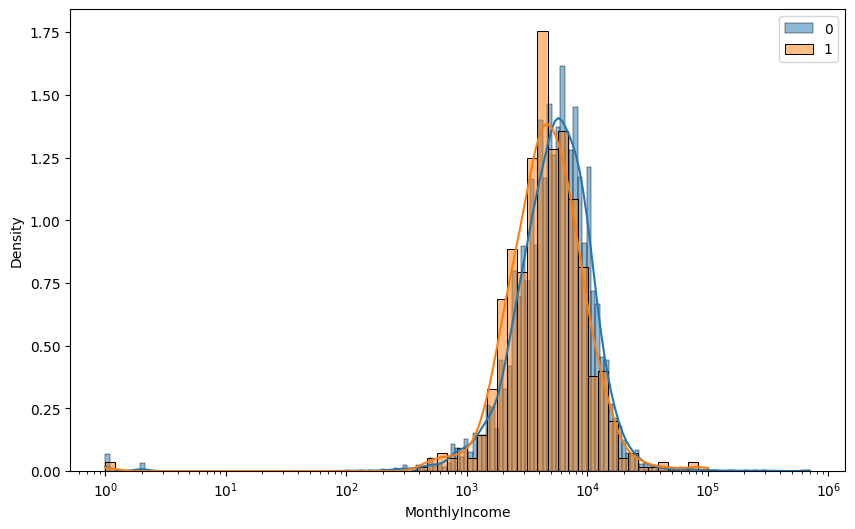

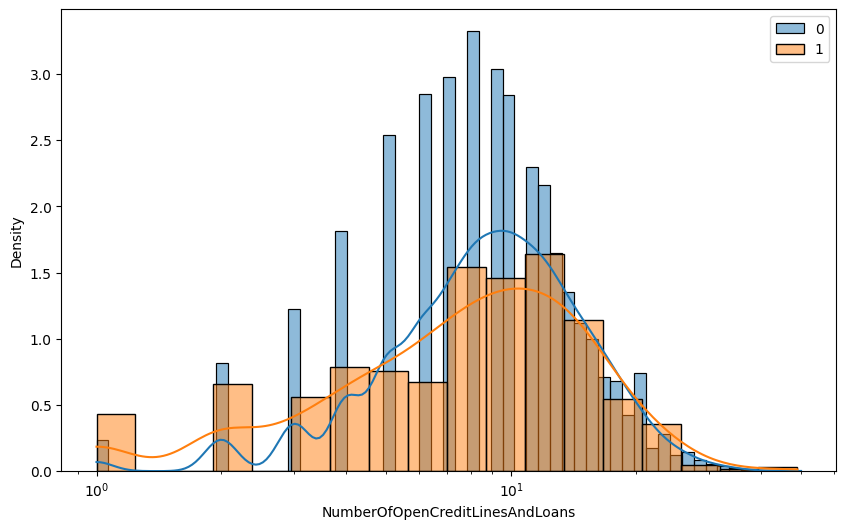

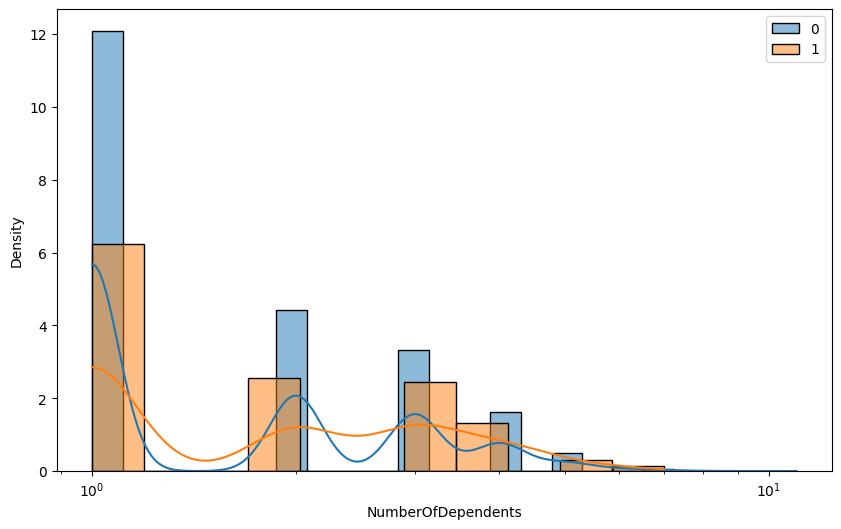

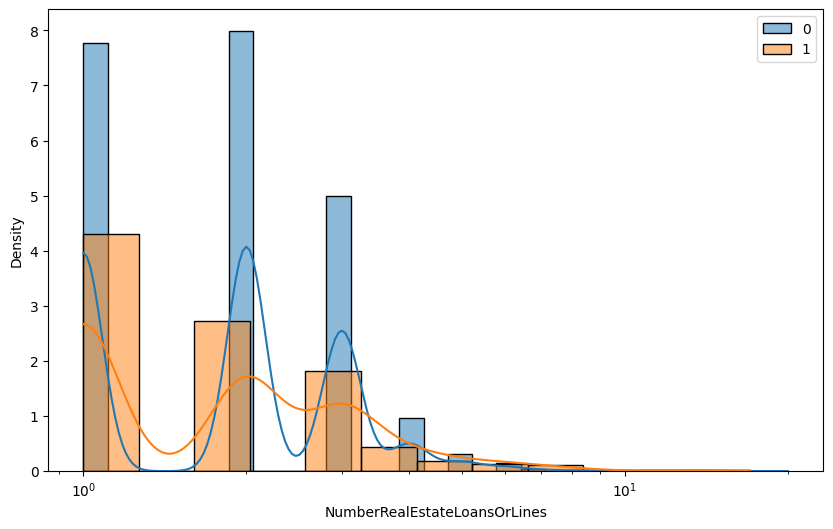

In [39]:
for col in features_num:
    plt.figure(figsize=(10,6))
    sns.histplot(train_set.loc[train_set[target] == 0] + 1, 
                x=col,
                kde=True,
                stat="density",
                log_scale=10,
                label="0")
    sns.histplot(train_set.loc[train_set[target] == 1] + 1, 
                x=col, 
                kde=True,
                stat="density",
                log_scale=10,
                label="1")
    plt.legend()
    plt.show()

*En Revolving hay una diferencia marcada en valores bajos, así que me la quedo.*

In [40]:
features_visual.append("RevolvingUtilizationOfUnsecuredLines")

*Del resto, la única que me deja tranquilo quedármela es "age": tiene un posible punto (más de 70 años) a partir del cual la relación de pagadores a no pagadores se dispara (vamos, que apenas hay impagadores), y algo parecido, aunque en menor medida, ocurre con los menores de 30-35:*

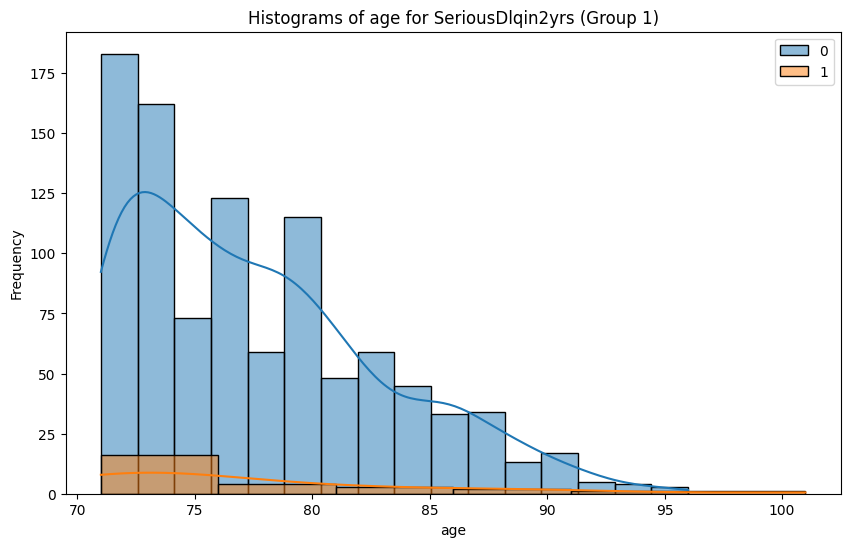

In [41]:
edad_cool = (train_set["age"] > 70)
bt.plot_grouped_histograms(train_set[edad_cool], cat_col = target, num_col= "age", group_size= 2)

*Me la quedo*

In [42]:
features_visual.append("age")

*Hay algunas que ya dejo en segunda división, "NumberOfDependents" y "NumberOfOpenCreditLinesAndLoans": en ellas o hay superposición o no se ven puntos de diferenciación claros*

*Tengo dudas, por el efecto de los outliers, en "MonthlyIncome" y "DebtRatio", así que las miro con "cariño":*

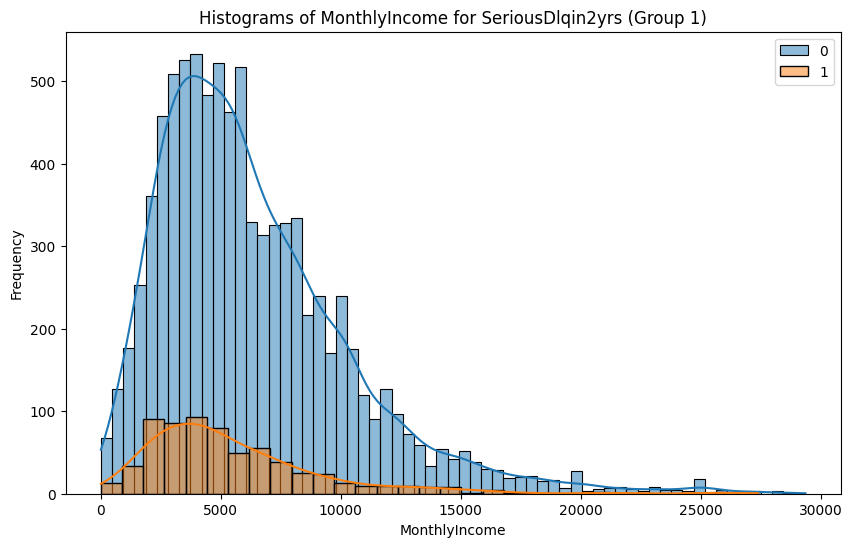

In [43]:
sin_monthlyincome_outliers = train_set["MonthlyIncome"] < 30000 # El valor se escoge mirando el diagrama de caja y no hay una regla fija: haz un diagrama de caja y observa que a partir de 20000 ya hay muchos outliers, escoger 30000 o 20000 es "indiferente" de primeras
bt.plot_grouped_histograms(train_set[sin_monthlyincome_outliers], cat_col= target, num_col= "MonthlyIncome", group_size= 2)

*Podría mandarla a segunda división, aunque existe un aumento importante de la relación pagadores sobre no-pagadores a partir de más de 10000 de monthly income que invita a quedársela en "primera". Para asegurarme, haré un test U de Mann-Whitney.*

In [44]:
cat_col = target
num_col = "MonthlyIncome"

grupo_a = train_set.loc[train_set[cat_col] == 0][num_col]
grupo_b = train_set.loc[train_set[cat_col] == 1][num_col]

u_stat, p_valor = mannwhitneyu(grupo_a, grupo_b)

print("Estadístico U:", u_stat)
print("Valor p:", p_valor)

Estadístico U: 3309844.0
Valor p: 4.937655211085432e-09


In [45]:
p_valor < 0.05

True

*Me la quedo*

In [46]:
features_visual.append("MonthlyIncome")

*Vamos con DebtRatio*

In [47]:
train_set["DebtRatio"].describe()

count    9452.000000
mean        0.486047
std         2.505031
min         0.000000
25%         0.146204
50%         0.297564
75%         0.477876
max        96.000000
Name: DebtRatio, dtype: float64

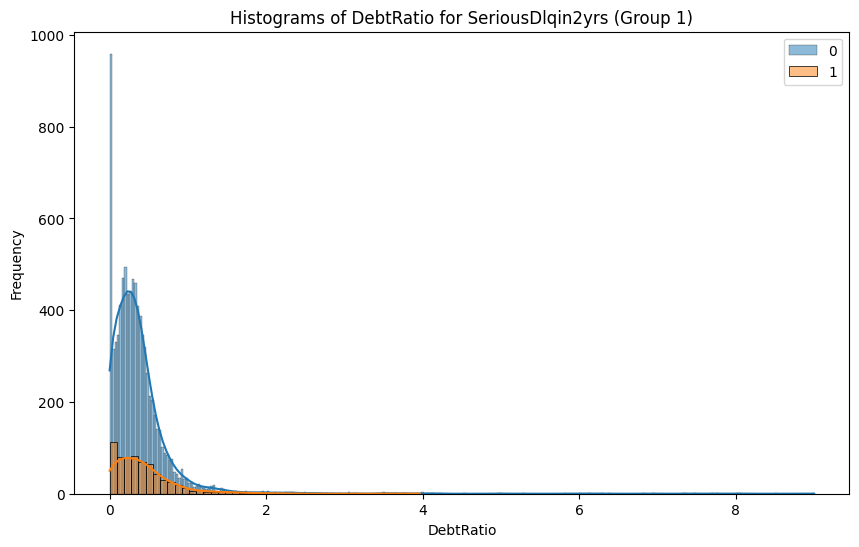

In [48]:
sin_debtratio_outliers = train_set["DebtRatio"] < 10
bt.plot_grouped_histograms(train_set[sin_debtratio_outliers], cat_col= target, num_col= "DebtRatio", group_size= 2)

*Tengo mis dudas, aunque el pico en 0 de pagadores me invita a quedármela, haré también un test:*

In [49]:
cat_col = target
num_col = "DebtRatio"

grupo_a = train_set.loc[train_set[cat_col] == 0][num_col]
grupo_b = train_set.loc[train_set[cat_col] == 1][num_col]

u_stat, p_valor = mannwhitneyu(grupo_a, grupo_b)

print("Estadístico U:", u_stat)
print("Valor p:", p_valor)

Estadístico U: 2623985.5
Valor p: 1.920288228898668e-05


In [50]:
p_valor < 0.05

True

*Me la quedo (p-value <<<< 0.05)*

In [51]:
features_visual.append("DebtRatio")

In [52]:
features_visual

['N30-59',
 'N60-89',
 'N90',
 'RevolvingUtilizationOfUnsecuredLines',
 'age',
 'MonthlyIncome',
 'DebtRatio']

*Sobre lo que tengo, hago un análisis de umbral de varianza:*

In [53]:
np.arange(0,1,0.1)

array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])

In [54]:
for umbral_varianza in np.arange(0,1,0.1):
    print(f"Para umbral = {umbral_varianza}")
    var_selector = VarianceThreshold(umbral_varianza)
    var_selector.fit(train_set[features_visual])
    print("Lista seleccionada por selector de Varianza", var_selector.get_feature_names_out())

Para umbral = 0.0
Lista seleccionada por selector de Varianza ['N30-59' 'N60-89' 'N90' 'RevolvingUtilizationOfUnsecuredLines' 'age'
 'MonthlyIncome' 'DebtRatio']
Para umbral = 0.1
Lista seleccionada por selector de Varianza ['N30-59' 'RevolvingUtilizationOfUnsecuredLines' 'age' 'MonthlyIncome'
 'DebtRatio']
Para umbral = 0.2
Lista seleccionada por selector de Varianza ['N30-59' 'age' 'MonthlyIncome' 'DebtRatio']
Para umbral = 0.30000000000000004
Lista seleccionada por selector de Varianza ['age' 'MonthlyIncome' 'DebtRatio']
Para umbral = 0.4
Lista seleccionada por selector de Varianza ['age' 'MonthlyIncome' 'DebtRatio']
Para umbral = 0.5
Lista seleccionada por selector de Varianza ['age' 'MonthlyIncome' 'DebtRatio']
Para umbral = 0.6000000000000001
Lista seleccionada por selector de Varianza ['age' 'MonthlyIncome' 'DebtRatio']
Para umbral = 0.7000000000000001
Lista seleccionada por selector de Varianza ['age' 'MonthlyIncome' 'DebtRatio']
Para umbral = 0.8
Lista seleccionada por selecto

*Vaya: lo que ocurre es que este selector se "come" las categóricas con pocas categorías y no equilibradas, por eso conviene aplicarlo solo a las variables continuas, donde nos confirma que no está mal quedárselas. Probablemente sea uno de los selectores que menos vas a usar.*

In [55]:
features_visual

['N30-59',
 'N60-89',
 'N90',
 'RevolvingUtilizationOfUnsecuredLines',
 'age',
 'MonthlyIncome',
 'DebtRatio']

4.4 **Selección por filtrado, Análisis ANOVA y Mutual Information**

*ANOVA sobre las numéricas:*

In [56]:
features_num

['RevolvingUtilizationOfUnsecuredLines',
 'age',
 'DebtRatio',
 'MonthlyIncome',
 'NumberOfOpenCreditLinesAndLoans',
 'NumberOfDependents',
 'NumberRealEstateLoansOrLines']

In [57]:
X_train = train_set[features_num]
y_train = train_set[target]

In [58]:
f_classif(X_train, y_train)

(array([8.29602605e+02, 1.11110548e+02, 3.27949461e-02, 3.11838171e+00,
        9.97516759e+00, 1.42688783e+01, 2.65741768e-02]),
 array([6.12914400e-175, 7.78315943e-026, 8.56297874e-001, 7.74459141e-002,
        1.59165160e-003, 1.59435900e-004, 8.70509418e-001]))

In [59]:
X_train = train_set[features_num]
y_train = train_set[target]

selector_num = SelectKBest(f_classif, k=3) # 3 numéricas + 3 categóricas = 6 features, el máximo que pide el enunciado
x_data_kbest = selector_num.fit_transform(X_train, y_train)

X_train_kbest = pd.DataFrame(x_data_kbest, columns = selector_num.get_feature_names_out())
X_train_kbest

,RevolvingUtilizationOfUnsecuredLines,age,NumberOfDependents
0,0.391240,68.0,0.0
1,0.906540,59.0,1.0
2,0.933223,52.0,3.0
3,0.857859,50.0,0.0
4,0.000000,61.0,1.0
...,...,...,...
9447,0.397822,53.0,0.0
9448,0.015171,76.0,0.0
9449,0.988201,62.0,0.0
9450,0.122072,41.0,1.0


In [60]:
features_filter = list(selector_num.get_feature_names_out())
features_filter

['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfDependents']

*Mutual Information para las categóricas:*

In [61]:
features_cat

['N30-59', 'N60-89', 'N90']

In [62]:
from sklearn.feature_selection import mutual_info_classif

X_train = train_set[features_cat]
y_train = train_set[target]

selector_cat = SelectKBest(mutual_info_classif, k=3)
x_data_kbest = selector_cat.fit_transform(X_train, y_train)

X_train_kbest = pd.DataFrame(x_data_kbest, columns = selector_cat.get_feature_names_out())
X_train_kbest

,N30-59,N60-89,N90
0,0,0,0
1,0,0,0
2,1,0,0
3,0,0,0
4,0,0,0
...,...,...,...
9447,0,0,0
9448,0,0,0
9449,0,0,0
9450,0,0,0


*Nos quedamos con las tres, sabiendo que podemos esperar más de N90 que de N30 y de N60.*

In [63]:
features_filter += features_cat

In [64]:
mutual_info_classif(X_train, y_train, random_state=42)

array([0.02514947, 0.01668426, 0.03397409])

*La información mutua, en el contexto de la teoría de la información, mide la cantidad de información que una variable aleatoria revela sobre otra.*  

*Se puede expresar en bits, nats o bans, dependiendo de la base del logaritmo utilizado.*  

*En el caso de mutual_info_classif, el resultado se expresa en nats, o unidades naturales de información, que se obtienen al usar logaritmos naturales (base e).*  

*Si quisiéramos expresar el resultado en bits, solo sería necesario dividir los nats entre el logaritmo neperiano de 2*

In [65]:
# Información Mutua en bits

mutual_info_classif(X_train, y_train, random_state=42) / np.log(2)

array([0.03628302, 0.02407031, 0.04901425])

*En resumen, podríamos fijar un umbral de corte arbitrario (es totalmente una regla del "dedo gordo" y depende siempre de nuestros datos). Fíjate en que los valores son muy pequeños (entre 0,017 y 0,034 nats): con un corte en 0,1, por ejemplo, no nos quedaríamos con ninguna, así que el umbral tendría que ser mucho más bajo. Como las tres mostraban diferencias claras en el análisis visual, nos quedamos con las tres.*

In [66]:
features_filter

['RevolvingUtilizationOfUnsecuredLines',
 'age',
 'NumberOfDependents',
 'N30-59',
 'N60-89',
 'N90']

4.5 **Selección por modelo**

*Vamos a hacerlo primero con sklearn y SelectFromModel empleando las features con las variables ya categorizadas (N30...). Ojo al hiperparámetro class_weight, que empleamos por lo desbalanceado que está el dataset de entrada.*

In [67]:
features = features_num + features_cat

rf_selector = RandomForestClassifier(random_state= 42, class_weight= "balanced") #

selector_modelo = SelectFromModel(estimator = rf_selector, threshold="median") # Nos quedamos con la mitad

selector_modelo.fit(train_set[features], train_set[target]) # X_train e y_train en los argumentos

features_modelo = list(selector_modelo.get_feature_names_out())
features_modelo

['RevolvingUtilizationOfUnsecuredLines',
 'age',
 'DebtRatio',
 'MonthlyIncome',
 'N90']

*Hmmm, bastante diferente de nuestras selecciones anteriores, las categóricas que prometían más se han caído en esta selección salvo una*

*Veamos cómo sería manualmente:*

In [68]:
rf_check = RandomForestClassifier(random_state= 42, class_weight= "balanced")

rf_check.fit(train_set[features], train_set[target])

df_importance= pd.DataFrame(rf_check.feature_importances_, columns = ["importance"], index = features).sort_values("importance",ascending = False)
df_importance

,importance
RevolvingUtilizationOfUnsecuredLines,0.275093
DebtRatio,0.130282
MonthlyIncome,0.120601
age,0.113560
N90,0.089300
NumberOfOpenCreditLinesAndLoans,0.082996
N30-59,0.080330
NumberOfDependents,0.036611
NumberRealEstateLoansOrLines,0.035826
N60-89,0.035399


*Cortando por la mediana*

In [69]:
df_importance.importance.median()

0.08614837893176767

In [70]:
df_importance[df_importance.importance > df_importance.importance.median()]

,importance
RevolvingUtilizationOfUnsecuredLines,0.275093
DebtRatio,0.130282
MonthlyIncome,0.120601
age,0.113560
N90,0.089300


4.6 **RFE**

In [71]:
rf_RFE = RandomForestClassifier(random_state= 42, class_weight= "balanced")

rfe = RFE(estimator = rf_RFE,
          n_features_to_select= 6, # Iterará hasta quedarse con 6
          step = 1)
# Número de iteraciones: (n_features - n_features_to_select) / step

rfe.fit(train_set[features], train_set[target])

,"estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance(e.g. `coef_`, `feature_importances_`).",RandomForestC...ndom_state=42)
,"n_features_to_select n_features_to_select: int or float, default=NoneThe number of features to select. If `None`, half of the features areselected. If integer, the parameter is the absolute number of featuresto select. If float between 0 and 1, it is the fraction of features toselect... versionchanged:: 0.24 Added float values for fractions.",6
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.",1
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case ofclass:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only available when `estimator` is a classifier.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: ``Estimator`` instanceThe fitted estimator used to select features.,RandomForestClassifier,RandomForestC...ndom_state=42)
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['RevolvingUtilizationOfUnsecuredLines','age','DebtRatio',...,'N30-59', 'N60-89','N90']"
n_features_ n_features_: intThe number of selected features.,int32,6
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,10


*NOTA: Podríamos haber probado con todas las features que ahora incluirían la versión numérica y la categorizada de NumberOf...*

In [72]:
features_RFE = list(rfe.get_feature_names_out())
features_RFE

['RevolvingUtilizationOfUnsecuredLines',
 'age',
 'DebtRatio',
 'MonthlyIncome',
 'NumberOfOpenCreditLinesAndLoans',
 'N90']

In [73]:
features_modelo

['RevolvingUtilizationOfUnsecuredLines',
 'age',
 'DebtRatio',
 'MonthlyIncome',
 'N90']

*No es igual que la selección por modelo.*

4.7 **Selección Secuencial (SFS)**

In [74]:
train_set[features].columns.tolist()

['RevolvingUtilizationOfUnsecuredLines',
 'age',
 'DebtRatio',
 'MonthlyIncome',
 'NumberOfOpenCreditLinesAndLoans',
 'NumberOfDependents',
 'NumberRealEstateLoansOrLines',
 'N30-59',
 'N60-89',
 'N90']

In [75]:
40 + 36 + 32 + 28 + 24

160

In [76]:
from sklearn.feature_selection import SequentialFeatureSelector

rf_SFS = RandomForestClassifier(class_weight= "balanced", random_state = 42)

sfs_forward = SequentialFeatureSelector(rf_SFS,
                                        n_features_to_select = 5,
                                        cv = 4,
                                        scoring = "balanced_accuracy", # o en regresión p.ej. "neg_root_mean_squared_error"
                                        n_jobs = -1)
# cuántos modelos entreno:
# 1a feature: 10 * 4 = 40
# 2a feature: 9 * 4 = 36
# 3a feature: 8 * 4 = 32
# 4a feature: 7 * 4 = 28
# 5a feature: 6 * 4 = 24

sfs_forward.fit(train_set[features], train_set[target])

,estimator estimator: estimator instanceAn unfitted estimator.,RandomForestC...ndom_state=42)
,"n_features_to_select n_features_to_select: ""auto"", int or float, default=""auto""If `""auto""`, the behaviour depends on the `tol` parameter:- if `tol` is not `None`, then features are selected while the score change does not exceed `tol`.- otherwise, half of the features are selected.If integer, the parameter is the absolute number of features to select.If float between 0 and 1, it is the fraction of features to select... versionadded:: 1.1 The option `""auto""` was added in version 1.1... versionchanged:: 1.3 The default changed from `""warn""` to `""auto""` in 1.3.",5
,"scoring scoring: str or callable, default=NoneScoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)`` that returns a single value. See :ref:`scoring_callable` for details.- `None`: the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.",'balanced_accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=5Determines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. In all othercases, :class:`~sklearn.model_selection.KFold` is used. These splittersare instantiated with `shuffle=False` so the splits will be the sameacross calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.",4
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel. When evaluating a new feature toadd or remove, the cross-validation procedure is parallel over thefolds.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",-1
,"tol tol: float, default=NoneIf the score is not incremented by at least `tol` between twoconsecutive feature additions or removals, stop adding or removing.`tol` can be negative when removing features using `direction=""backward""`.`tol` is required to be strictly positive when doing forward selection.It can be useful to reduce the number of features at the cost of a smalldecrease in the score.`tol` is enabled only when `n_features_to_select` is `""auto""`... versionadded:: 1.1",None
,"direction direction: {'forward', 'backward'}, default='forward'Whether to perform forward selection or backward selection.",'forward'
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['RevolvingUtilizationOfUnsecuredLines','age','DebtRatio',...,'N30-59', 'N60-89','N90']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,10
n_features_to_select_ n_features_to_select_: intThe number of features that were selected.,int32,5


In [77]:
features_SFS = list(sfs_forward.get_feature_names_out())
features_SFS

['NumberOfDependents',
 'NumberRealEstateLoansOrLines',
 'N30-59',
 'N60-89',
 'N90']

In [78]:
features_RFE

['RevolvingUtilizationOfUnsecuredLines',
 'age',
 'DebtRatio',
 'MonthlyIncome',
 'NumberOfOpenCreditLinesAndLoans',
 'N90']

In [79]:
features_modelo

['RevolvingUtilizationOfUnsecuredLines',
 'age',
 'DebtRatio',
 'MonthlyIncome',
 'N90']

In [80]:
features_filter

['RevolvingUtilizationOfUnsecuredLines',
 'age',
 'NumberOfDependents',
 'N30-59',
 'N60-89',
 'N90']

In [81]:
features_visual

['N30-59',
 'N60-89',
 'N90',
 'RevolvingUtilizationOfUnsecuredLines',
 'age',
 'MonthlyIncome',
 'DebtRatio']

*Tenemos para todos los gustos*

4.8 **Hard Voting**


*El hard-voting no es más que contar las veces que aparece repetida cada feature en las selecciones anteriores y quedarnos con las "más votadas". En este caso nos quedaremos con las 6 más votadas, porque el enunciado nos pide no superar 6 features. Usaremos `Counter` del módulo collections.*

In [82]:
lista_total = features_visual + features_filter + features_modelo + features_RFE + features_SFS
votaciones = Counter(lista_total)
votaciones

Counter({'N90': 5,
         'RevolvingUtilizationOfUnsecuredLines': 4,
         'age': 4,
         'N30-59': 3,
         'N60-89': 3,
         'MonthlyIncome': 3,
         'DebtRatio': 3,
         'NumberOfDependents': 2,
         'NumberOfOpenCreditLinesAndLoans': 1,
         'NumberRealEstateLoansOrLines': 1})

In [83]:
escrutinio = pd.DataFrame(votaciones.values(), columns = ["Votos"], index = votaciones.keys()).sort_values("Votos", ascending = False)
escrutinio


,Votos
N90,5
RevolvingUtilizationOfUnsecuredLines,4
age,4
N30-59,3
N60-89,3
MonthlyIncome,3
DebtRatio,3
NumberOfDependents,2
NumberOfOpenCreditLinesAndLoans,1
NumberRealEstateLoansOrLines,1


In [84]:
features_hard_voting = escrutinio["Votos"].nlargest(6).index.to_list()
features_hard_voting

['N90',
 'RevolvingUtilizationOfUnsecuredLines',
 'age',
 'N30-59',
 'N60-89',
 'MonthlyIncome']

5. **Modelado**



*Por simplificar y para evitarnos el escalado vamos a probar con RandomForest, XGBoost y LightGBM*

In [85]:
nombres = [f"Seleccion {nombre}" for nombre in ["visual", "filter", "modelo", "rfe", "sfs", "voting"]]
model_names = ["Random Forest","XGBoost", "LightGBM"]

rf_clf = RandomForestClassifier(class_weight= "balanced", random_state= 42)
xg_clf = XGBClassifier(random_state  = 42, scale_pos_weight = len(train_set[train_set[target] == 0])/len(train_set[train_set[target] == 1]))
lgb_clf = LGBMClassifier(class_weight= "balanced", random_state= 42, verbose = -100, n_jobs= -1)

models = [rf_clf, xg_clf, lgb_clf]
resultados = []

for indice, lista in enumerate([features_visual, features_filter, features_modelo, features_RFE, features_SFS, features_hard_voting]):
    X_train = train_set[lista]
    y_train = train_set[target]
    
    for model_name, modelo in zip(model_names, models):
        metrica = np.mean(cross_val_score(modelo, X_train, y_train, cv = 5, scoring = "balanced_accuracy"))
        data = {
            "features_list": nombres[indice],
            "model": model_name,
            "avg. recall": metrica
        }
        print(data)
        resultados.append(data.copy())
df_resultados = pd.DataFrame(resultados)
df_resultados.sort_values("avg. recall", ascending = False)


{'features_list': 'Seleccion visual', 'model': 'Random Forest', 'avg. recall': 0.653278047527366}


{'features_list': 'Seleccion visual', 'model': 'XGBoost', 'avg. recall': 0.6512736578656659}


{'features_list': 'Seleccion visual', 'model': 'LightGBM', 'avg. recall': 0.718585685857393}


{'features_list': 'Seleccion filter', 'model': 'Random Forest', 'avg. recall': 0.6564378643769899}


{'features_list': 'Seleccion filter', 'model': 'XGBoost', 'avg. recall': 0.6661299652658093}


{'features_list': 'Seleccion filter', 'model': 'LightGBM', 'avg. recall': 0.7332472060006328}


... (9 outputs left out)

{'features_list': 'Seleccion voting', 'model': 'Random Forest', 'avg. recall': 0.6536123399993767}


{'features_list': 'Seleccion voting', 'model': 'XGBoost', 'avg. recall': 0.6497162495024826}


{'features_list': 'Seleccion voting', 'model': 'LightGBM', 'avg. recall': 0.7262028652703068}


,features_list,model,avg. recall
14,Seleccion sfs,LightGBM,0.736700
5,Seleccion filter,LightGBM,0.733247
13,Seleccion sfs,XGBoost,0.726941
17,Seleccion voting,LightGBM,0.726203
2,Seleccion visual,LightGBM,0.718586
12,Seleccion sfs,Random Forest,0.717596
8,Seleccion modelo,LightGBM,0.709230
11,Seleccion rfe,LightGBM,0.705072
4,Seleccion filter,XGBoost,0.666130
3,Seleccion filter,Random Forest,0.656438


*Nos quedamos con LightGBM, que gana con todas las listas. Las dos mejores selecciones son la secuencial (SFS, 5 features) y la de filtrado (6 features), prácticamente empatadas. Como SFS escoge las features mirando directamente la validación cruzada sobre el mismo train, su resultado tiende a ser optimista (puede sobreajustarse a esos datos), así que vamos a ajustar el modelo con las dos y, como referencia, también con todas las features.*

In [86]:
features_SFS

['NumberOfDependents',
 'NumberRealEstateLoansOrLines',
 'N30-59',
 'N60-89',
 'N90']

6. **Ajuste fino y evaluación**

*Sobre SFS*

In [87]:
### LightGBM

param_grid = {
    "n_estimators": [100,200],
    "learning_rate": [0.1,0.5,1],
    "max_depth": [5,10,15],
    "min_data_in_leaf": [1,10,20,100],
    "class_weight":["balanced",None]
}

lgb_clf = LGBMClassifier(random_state = 42, verbose = -100)

lgb_grid = GridSearchCV(lgb_clf,
                       param_grid= param_grid,
                       cv = 5,
                       scoring= "balanced_accuracy",
                       n_jobs=-1)

lgb_grid.fit(train_set[features_SFS], train_set[target])

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LGBMClassifie... verbose=-100)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'class_weight': ['balanced', None], 'learning_rate': [0.1, 0.5, ...], 'max_depth': [5, 10, ...], 'min_data_in_leaf': [1, 10, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'balanced_accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for ca

In [88]:
lgb_grid.best_params_

{'class_weight': 'balanced',
 'learning_rate': 0.1,
 'max_depth': 5,
 'min_data_in_leaf': 100,
 'n_estimators': 200}

In [89]:
lgb_grid.best_score_

0.7466702308255084

In [90]:
X_test = test_set[features_SFS]
y_test = test_set[target]

In [91]:
y_pred = lgb_grid.best_estimator_.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.84      0.90      2197
           1       0.22      0.59      0.32       167

    accuracy                           0.82      2364
   macro avg       0.59      0.71      0.61      2364
weighted avg       0.91      0.82      0.86      2364



In [92]:
features_SFS

['NumberOfDependents',
 'NumberRealEstateLoansOrLines',
 'N30-59',
 'N60-89',
 'N90']

*Sobre filtrado*

In [93]:

param_grid = {
    "n_estimators": [100,200],
    "learning_rate": [0.1,0.5,1],
    "max_depth": [5,10,15],
    "min_data_in_leaf": [1,10,20,100],
    "class_weight":["balanced",None]
}

lgb_clf = LGBMClassifier(random_state = 42, verbose = -100, n_jobs = -1)

lgb_grid_2 = GridSearchCV(lgb_clf,
                       param_grid= param_grid,
                       cv = 5,
                       scoring= "balanced_accuracy",
                       n_jobs=1)

lgb_grid_2.fit(train_set[features_filter], train_set[target])

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LGBMClassifie... verbose=-100)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'class_weight': ['balanced', None], 'learning_rate': [0.1, 0.5, ...], 'max_depth': [5, 10, ...], 'min_data_in_leaf': [1, 10, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'balanced_accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for cal

In [94]:
lgb_grid_2.best_params_

{'class_weight': 'balanced',
 'learning_rate': 0.1,
 'max_depth': 5,
 'min_data_in_leaf': 100,
 'n_estimators': 100}

In [95]:
lgb_grid_2.best_score_

0.7639290091954736

In [96]:
X_test = test_set[features_filter]
y_test = test_set[target]

In [97]:
y_pred = lgb_grid_2.best_estimator_.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.80      0.88      2197
           1       0.21      0.69      0.33       167

    accuracy                           0.80      2364
   macro avg       0.59      0.75      0.60      2364
weighted avg       0.92      0.80      0.84      2364



In [98]:
features_filter

['RevolvingUtilizationOfUnsecuredLines',
 'age',
 'NumberOfDependents',
 'N30-59',
 'N60-89',
 'N90']

*Sobre todas las variables*

In [99]:

param_grid = {
    "n_estimators": [100,200],
    "learning_rate": [0.1,0.5,1],
    "max_depth": [5,10,15],
    "min_data_in_leaf": [1,10,20,100],
    "class_weight":["balanced",None]
}

lgb_clf = LGBMClassifier(random_state = 42, verbose = -100, n_jobs = -1)

lgb_grid_3 = GridSearchCV(lgb_clf,
                       param_grid= param_grid,
                       cv = 5,
                       scoring= "balanced_accuracy",
                       n_jobs=1)

lgb_grid_3.fit(train_set[features], train_set[target])

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LGBMClassifie... verbose=-100)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'class_weight': ['balanced', None], 'learning_rate': [0.1, 0.5, ...], 'max_depth': [5, 10, ...], 'min_data_in_leaf': [1, 10, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'balanced_accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for cal

In [100]:
lgb_grid_3.best_params_

{'class_weight': 'balanced',
 'learning_rate': 0.1,
 'max_depth': 5,
 'min_data_in_leaf': 100,
 'n_estimators': 100}

In [101]:
lgb_grid_3.best_score_

0.7552213289694476

In [102]:
X_test = test_set[features]
y_test = test_set[target]

In [103]:
y_pred = lgb_grid_3.best_estimator_.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.83      0.90      2197
           1       0.23      0.67      0.35       167

    accuracy                           0.82      2364
   macro avg       0.60      0.75      0.62      2364
weighted avg       0.92      0.82      0.86      2364



*Comparando las tres opciones contra test (recall medio, la fila macro avg del recall):*
* *SFS (5 features): 0,71. Era la mejor en validación cruzada antes de ajustar hiperparámetros, pero es la que peor generaliza: un ejemplo de lo optimista que puede ser una selección hecha a base de validación cruzada sobre el mismo train.*
* *Filtrado (6 features): 0,75.*
* *Todas las features (10): 0,75.*

*La selección por filtrado consigue el mismo resultado en test que el modelo con todas las features, con 4 features menos. Ese es el tipo de compromiso que buscamos: no mejoramos la métrica, pero simplificamos el modelo sin perder rendimiento. Nos quedaríamos con LightGBM y la selección por filtrado.*

In [104]:
features

['RevolvingUtilizationOfUnsecuredLines',
 'age',
 'DebtRatio',
 'MonthlyIncome',
 'NumberOfOpenCreditLinesAndLoans',
 'NumberOfDependents',
 'NumberRealEstateLoansOrLines',
 'N30-59',
 'N60-89',
 'N90']

### EXTRA

Aplica la PCA como método de selección, escoge un número de componentes en función de la varianza explicada y crea un dataset con el que entrenar el mismo tipo de modelo ganador de la parte general. Entrénalo y evalúalo contra test, comenta el resultado.

In [105]:
from sklearn.preprocessing import StandardScaler

X_train = train_set[features]
X_test = test_set[features]
y_train = train_set[target]
y_test = test_set[target]

# Como vimos en la unidad de PCA, hay que escalar antes: si no, la variable con más escala (MonthlyIncome) acapara toda la varianza
scaler = StandardScaler()
X_train_scal = scaler.fit_transform(X_train)
X_test_scal = scaler.transform(X_test)

pca = PCA()
pca.fit(X_train_scal)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [106]:
pca.explained_variance_ratio_

array([0.2019648 , 0.15035084, 0.11922237, 0.10292148, 0.09136769,
       0.07944477, 0.06952303, 0.06914786, 0.06159212, 0.05446503])

------------------------------------------
Porcentaje de varianza explicada acumulada
------------------------------------------
[0.2019648  0.35231564 0.47153801 0.57445949 0.66582719 0.74527195
 0.81479498 0.88394285 0.94553497 1.        ]


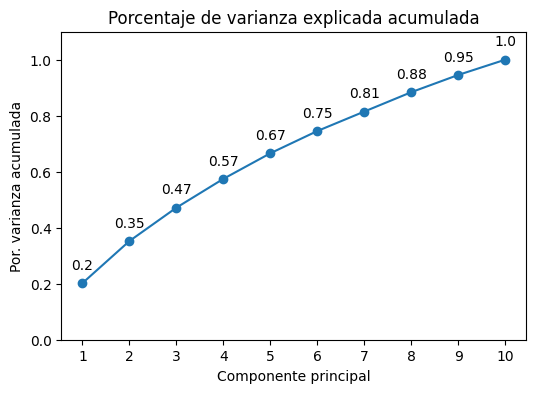

In [107]:
prop_varianza_acum = pca.explained_variance_ratio_.cumsum()
print('------------------------------------------')
print('Porcentaje de varianza explicada acumulada')
print('------------------------------------------')
print(prop_varianza_acum)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6, 4))
ax.plot(
    np.arange(len(X_train.columns)) + 1,
    prop_varianza_acum,
    marker = 'o'
)

for x, y in zip(np.arange(len(X_train.columns)) + 1, prop_varianza_acum):
    label = round(y, 2)
    ax.annotate(
        label,
        (x,y),
        textcoords="offset points",
        xytext=(0,10),
        ha='center'
    )
    
ax.set_ylim(0, 1.1)
ax.set_xticks(np.arange(pca.n_components_) + 1)
ax.set_title('Porcentaje de varianza explicada acumulada')
ax.set_xlabel('Componente principal')
ax.set_ylabel('Por. varianza acumulada');

*Nos quedamos con el número de componentes necesario para explicar al menos el 90% de la varianza:*

In [108]:
X_train_pca = pca.transform(X_train_scal)
X_test_pca = pca.transform(X_test_scal)

n_pcs = np.argmax(prop_varianza_acum >= 0.90) + 1
n_pcs

9

In [109]:
lgb_clf_pca = LGBMClassifier(**lgb_grid_3.best_params_, random_state = 42, verbose = -100)
lgb_clf_pca.fit(X_train_pca[:, :n_pcs], y_train)
y_pred = lgb_clf_pca.predict(X_test_pca[:, :n_pcs])
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.84      0.90      2197
           1       0.24      0.65      0.35       167

    accuracy                           0.83      2364
   macro avg       0.60      0.75      0.63      2364
weighted avg       0.92      0.83      0.86      2364



*Al escalar antes, la varianza ya no la acapara una sola variable: necesitamos 9 de las 10 componentes para llegar al 90%. Con ellas el modelo consigue un recall medio de 0,75 en test, el mismo que con todas las features o con la selección por filtrado, pero sin ninguna ventaja: apenas reducimos dimensiones y perdemos la interpretabilidad de las features originales. En este dataset, con pocas features y poco correladas entre sí, la PCA no compensa como método de selección.*